## 0. Install (run once)

In [1]:
!pip install -q pandas numpy scikit-learn xgboost tensorflow shap plotly mlxtend statsmodels prophet holidays requests beautifulsoup4 streamlit joblib seaborn matplotlib

## 1. Imports and configuration

In [2]:
import os, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import requests, holidays
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

LAT, LON = 11.0168, 76.9558          # Coimbatore - change to your location
START, END = "2023-01-01", "2025-12-31"
print("Setup OK")

Setup OK


## 2. Data collection: weather API, holidays, optional web scraping

In [3]:
def get_weather(start, end, lat=LAT, lon=LON):
    """Daily max temperature and rainfall from Open-Meteo (free, no key). Falls back to synthetic if offline."""
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = dict(latitude=lat, longitude=lon, start_date=start, end_date=end,
                  daily="temperature_2m_max,precipitation_sum", timezone="Asia/Kolkata")
    try:
        r = requests.get(url, params=params, timeout=30)
        r.raise_for_status()
        d = r.json()["daily"]
        w = pd.DataFrame({"date": pd.to_datetime(d["time"]),
                          "temp_max": d["temperature_2m_max"],
                          "rain_mm": d["precipitation_sum"]})
        w["weather_source"] = "open-meteo"
    except Exception as e:
        print("Weather API failed, using synthetic weather:", e)
        rng = np.random.default_rng(SEED)
        dates = pd.date_range(start, end)
        doy = dates.dayofyear.values
        temp = 31 + 3*np.sin((doy-90)/365*2*np.pi) + rng.normal(0, 1.2, len(dates))
        rain = np.where(rng.random(len(dates)) < 0.25, rng.exponential(10, len(dates)), 0)
        w = pd.DataFrame({"date": dates, "temp_max": temp, "rain_mm": rain, "weather_source": "synthetic"})
    w["temp_max"] = w["temp_max"].interpolate().bfill().ffill()
    w["rain_mm"] = w["rain_mm"].fillna(0)
    return w

weather = get_weather(START, END)

years = range(pd.Timestamp(START).year, pd.Timestamp(END).year + 1)
try:
    hol = holidays.India(subdiv="TN", years=years)
except Exception:
    hol = holidays.India(years=years)
weather["is_holiday"] = weather["date"].dt.date.map(lambda d: int(d in hol))

print(weather.shape, "| source:", weather.weather_source.iloc[0], "| holidays:", weather.is_holiday.sum())
weather.head()

(1096, 5) | source: open-meteo | holidays: 71


,date,temp_max,rain_mm,weather_source,is_holiday
0,2023-01-01,30.0,0.0,open-meteo,0
1,2023-01-02,29.4,0.0,open-meteo,0
2,2023-01-03,30.1,0.0,open-meteo,0
3,2023-01-04,29.8,0.5,open-meteo,0
4,2023-01-05,28.8,0.0,open-meteo,0


In [4]:
# OPTIONAL: web-scraping template for menu / price / rating data (the "web-scraped dataset" part of your rubric).
# Check the site's robots.txt and terms first. Selectors below are placeholders - inspect the page (F12) and edit them.
from bs4 import BeautifulSoup

RUN_SCRAPER = False
SCRAPE_URL = "https://example.com/restaurant-menu"

def scrape_menu(url):
    headers = {"User-Agent": "Mozilla/5.0 (academic project)"}
    html = requests.get(url, headers=headers, timeout=30).text
    soup = BeautifulSoup(html, "html.parser")
    rows = []
    for card in soup.select(".menu-item"):                 # <- edit selector
        name = card.select_one(".item-name")               # <- edit selector
        price = card.select_one(".item-price")             # <- edit selector
        rows.append({"item": name.get_text(strip=True) if name else None,
                     "price": price.get_text(strip=True) if price else None})
    return pd.DataFrame(rows)

if RUN_SCRAPER:
    menu = scrape_menu(SCRAPE_URL)
    menu.to_csv("scraped_menu.csv", index=False)
    print(menu.head())

## 3. Build the item-level dataset (SIMULATED - replace with your real log)

In [5]:
# item: (base servings prepared, temperature sensitivity, rain sensitivity)
ITEMS = {"Rice Meal": (250, 0.00, 0.05), "Biryani": (120, -0.02, 0.10), "Dosa": (150, -0.02, 0.10),
         "Idli": (140, -0.01, 0.08), "Veg Noodles": (90, 0.00, 0.05), "Samosa": (100, -0.03, 0.20),
         "Cold Drink": (130, 0.10, -0.15), "Filter Coffee": (160, -0.05, 0.15)}

rng = np.random.default_rng(SEED)
rows = []
for _, w in weather.iterrows():
    wk = 1 if w.date.dayofweek >= 5 else 0
    for item, (base, ts, rs) in ITEMS.items():
        t_term = max(1 + ts * (w.temp_max - 32) / 3, 0.3)
        r_term = max(1 + rs * min(w.rain_mm, 40) / 10, 0.3)
        demand = base * (1 - 0.40*wk) * (1 - 0.70*w.is_holiday) * t_term * r_term * rng.lognormal(0, 0.08)
        prepared = base * 1.12 * rng.normal(1, 0.02)          # kitchen prepares a near-fixed amount
        sold = min(demand, prepared)
        rows.append((w.date, item, round(prepared), round(sold), round(prepared) - round(sold)))

items_df = pd.DataFrame(rows, columns=["date", "item", "prepared", "sold", "waste_units"])
items_df = items_df.merge(weather[["date", "temp_max", "rain_mm", "is_holiday"]], on="date")
items_df.to_csv("item_level_data.csv", index=False)

# --- To use REAL data instead, uncomment and adapt: ---
# items_df = pd.read_csv("my_canteen_log.csv", parse_dates=["date"])
# items_df["waste_units"] = items_df["prepared"] - items_df["sold"]
# items_df = items_df.merge(weather[["date","temp_max","rain_mm","is_holiday"]], on="date", how="left")

print(items_df.shape)
items_df.head()

(8768, 8)


,date,item,prepared,sold,waste_units,temp_max,rain_mm,is_holiday
0,2023-01-01,Rice Meal,274,154,120,30.0,0.0,0
1,2023-01-01,Biryani,137,77,60,30.0,0.0,0
2,2023-01-01,Dosa,164,78,86,30.0,0.0,0
3,2023-01-01,Idli,156,85,71,30.0,0.0,0
4,2023-01-01,Veg Noodles,99,54,45,30.0,0.0,0


## 4. Feature engineering (daily level)

In [6]:
daily = (items_df.groupby("date")
         .agg(prepared=("prepared", "sum"), sold=("sold", "sum"), waste_units=("waste_units", "sum"),
              temp_max=("temp_max", "first"), rain_mm=("rain_mm", "first"), is_holiday=("is_holiday", "first"))
         .reset_index())

daily["dow"] = daily.date.dt.dayofweek
daily["month"] = daily.date.dt.month
daily["is_weekend"] = (daily.dow >= 5).astype(int)
daily["lag_1"] = daily.waste_units.shift(1)
daily["lag_7"] = daily.waste_units.shift(7)
daily["roll7"] = daily.waste_units.shift(1).rolling(7).mean()

HIST = ["lag_1", "lag_7", "roll7", "dow", "month", "is_weekend"]   # history + calendar
EXT  = ["temp_max", "rain_mm", "is_holiday"]                       # external signals
ALL  = HIST + EXT
TARGET = "waste_units"

full = daily.dropna().reset_index(drop=True)
W = 7                                                              # LSTM look-back window
m = full.iloc[W-1:].reset_index(drop=True)                         # rows shared by every model

n = len(m)
i_tr, i_va = int(0.70*n), int(0.85*n)                              # chronological split
tr, va, te = m.iloc[:i_tr], m.iloc[i_tr:i_va], m.iloc[i_va:]
print(f"train={len(tr)}  val={len(va)}  test={len(te)}")
m.head()

train=758  val=162  test=163


,date,prepared,sold,waste_units,temp_max,rain_mm,is_holiday,dow,month,is_weekend,lag_1,lag_7,roll7
0,2023-01-14,1269,680,589,30.5,0.0,0,5,1,1,173.0,601.0,268.285714
1,2023-01-15,1278,200,1078,30.7,0.0,1,6,1,1,589.0,560.0,266.571429
2,2023-01-16,1272,349,923,31.2,0.0,1,0,1,0,1078.0,153.0,340.571429
3,2023-01-17,1273,344,929,30.6,0.0,1,1,1,0,923.0,157.0,450.571429
4,2023-01-18,1282,1164,118,30.7,0.0,0,2,1,0,929.0,137.0,560.857143


## 5. Exploratory data analysis

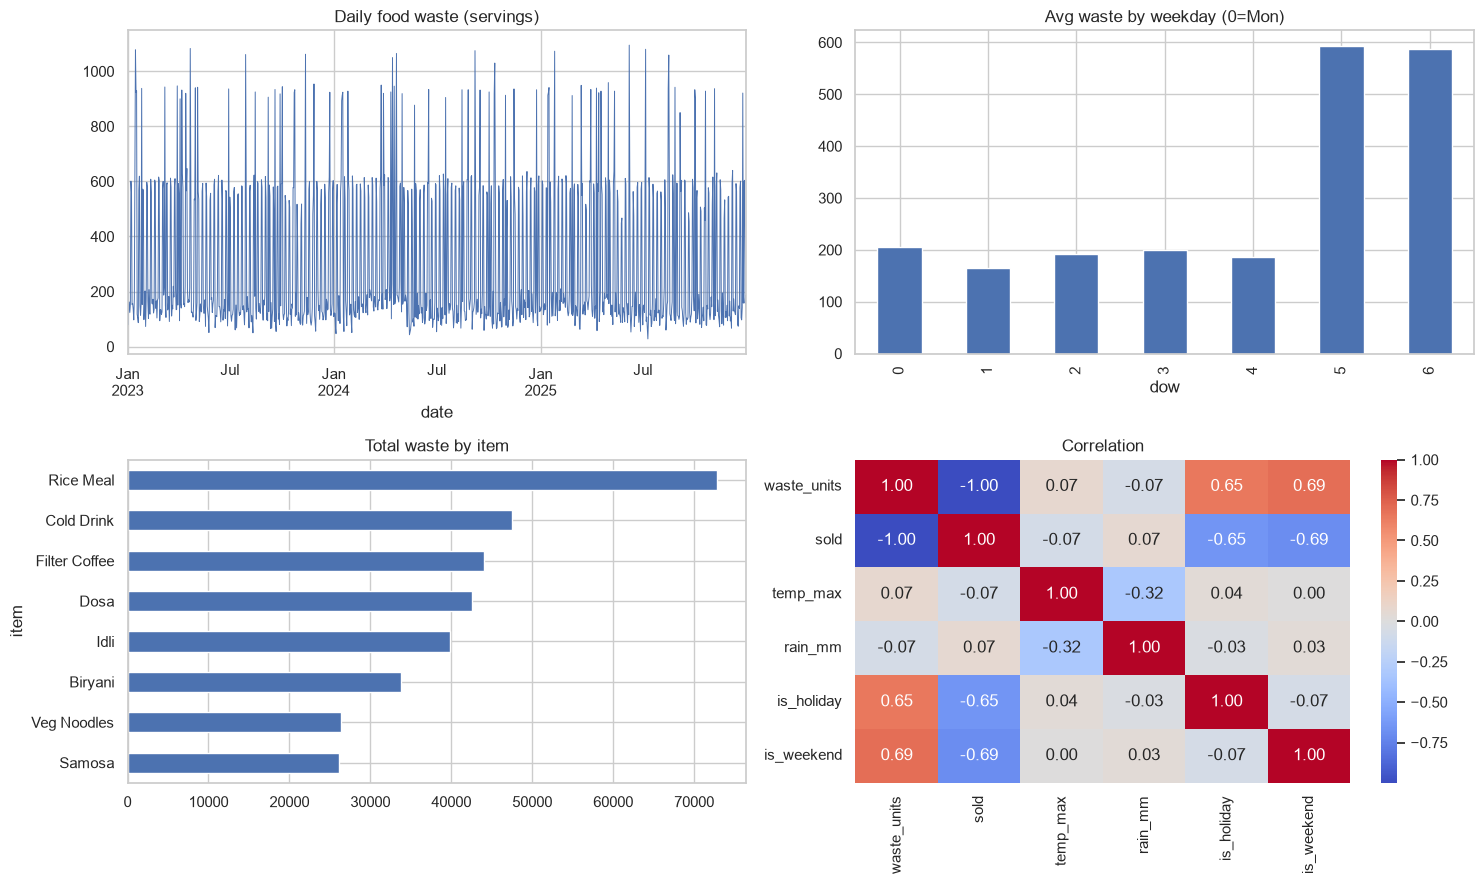

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
daily.set_index("date")["waste_units"].plot(ax=ax[0,0], lw=0.7, title="Daily food waste (servings)")
daily.groupby("dow")["waste_units"].mean().plot.bar(ax=ax[0,1], title="Avg waste by weekday (0=Mon)")
items_df.groupby("item")["waste_units"].sum().sort_values().plot.barh(ax=ax[1,0], title="Total waste by item")
sns.heatmap(daily[["waste_units", "sold", "temp_max", "rain_mm", "is_holiday", "is_weekend"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1,1]); ax[1,1].set_title("Correlation")
plt.tight_layout(); plt.show()

monthly = daily.groupby(daily.date.dt.to_period("M"))["waste_units"].sum()
monthly.index = monthly.index.to_timestamp()
px.line(monthly, title="Monthly total waste (seasonality)").show()

## 6. Consumption pattern analysis

### 6a. K-Means clustering of days by consumption behaviour

In [8]:
cl_feat = ["sold", "waste_units", "temp_max", "rain_mm", "is_weekend", "is_holiday"]
Xc = StandardScaler().fit_transform(daily[cl_feat])

scores = {k: silhouette_score(Xc, KMeans(k, n_init=10, random_state=SEED).fit_predict(Xc)) for k in range(2, 7)}
best_k = max(scores, key=scores.get)
print("Silhouette scores:", {k: round(v, 3) for k, v in scores.items()}, "-> best k =", best_k)

daily["cluster"] = KMeans(best_k, n_init=10, random_state=SEED).fit_predict(Xc)
pc = PCA(2).fit_transform(Xc)
px.scatter(x=pc[:, 0], y=pc[:, 1], color=daily.cluster.astype(str),
           title="Day clusters (PCA)", labels={"x": "PC1", "y": "PC2"}).show()
daily.groupby("cluster")[cl_feat].mean().round(2)

Silhouette scores: {2: 0.537, 3: 0.582, 4: 0.587, 5: 0.505, 6: 0.464} -> best k = 4


,sold,waste_units,temp_max,rain_mm,is_weekend,is_holiday
cluster,,,,,,
0,1143.72,133.38,31.81,1.48,0.00,0.0
1,700.84,576.22,31.69,2.83,1.00,0.0
2,325.75,950.38,32.02,2.60,0.17,1.0
3,1130.68,144.72,28.64,21.30,0.16,0.0


### 6b. Association rules (items ordered together)

In [9]:
# Orders are simulated here; replace with real bill/order data (one row per order, list of items).
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

rng2 = np.random.default_rng(SEED)
names = list(ITEMS)
pop = np.array([b for b, _, _ in ITEMS.values()], dtype=float); pop /= pop.sum()
orders = []
for _ in range(5000):
    basket = set(rng2.choice(names, size=rng2.integers(1, 3), p=pop, replace=False))
    if "Rice Meal" in basket and rng2.random() < 0.5: basket.add("Cold Drink")
    if "Dosa" in basket and rng2.random() < 0.6:      basket.add("Filter Coffee")
    if "Samosa" in basket and rng2.random() < 0.5:    basket.add("Filter Coffee")
    orders.append(list(basket))

te_enc = TransactionEncoder()
basket_df = pd.DataFrame(te_enc.fit(orders).transform(orders), columns=te_enc.columns_)
freq = apriori(basket_df, min_support=0.03, use_colnames=True)
rules = association_rules(freq, metric="lift", min_threshold=1.1)
rules[["antecedents", "consequents", "support", "confidence", "lift"]].sort_values("lift", ascending=False).head(10)

,antecedents,consequents,support,confidence,lift
3,frozenset({Filter Coffee}),frozenset({Dosa}),0.1338,0.366375,1.828217
2,frozenset({Dosa}),frozenset({Filter Coffee}),0.1338,0.667665,1.828217
1,frozenset({Cold Drink}),frozenset({Rice Meal}),0.1710,0.544239,1.694394
0,frozenset({Rice Meal}),frozenset({Cold Drink}),0.1710,0.532379,1.694394
4,frozenset({Samosa}),frozenset({Filter Coffee}),0.0752,0.567976,1.555246
5,frozenset({Filter Coffee}),frozenset({Samosa}),0.0752,0.205915,1.555246
9,frozenset({Rice Meal}),"frozenset({Filter Coffee, Cold Drink})",0.0328,0.102117,1.528699
6,"frozenset({Filter Coffee, Cold Drink})",frozenset({Rice Meal}),0.0328,0.491018,1.528699
7,"frozenset({Rice Meal, Filter Coffee})",frozenset({Cold Drink}),0.0328,0.453039,1.441880
8,frozenset({Cold Drink}),"frozenset({Rice Meal, Filter Coffee})",0.0328,0.104392,1.441880


## 7. Models: baselines, ML, LSTM, hybrid

In [10]:
def evaluate(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)),
            "MAPE%": np.mean(np.abs((y - p) / np.maximum(y, 1))) * 100,
            "R2": r2_score(y, p)}

y_tr, y_va, y_te = tr[TARGET].values, va[TARGET].values, te[TARGET].values
results, preds_val, preds_test = {}, {}, {}

# ---- Baselines ----
preds_test["Naive (yesterday)"] = te["lag_1"].values
preds_test["Moving Avg (7d)"] = te["roll7"].values

# SARIMA (multi-step forecast over the whole test window)
try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    series = m.set_index("date")[TARGET].asfreq("D")
    fit = SARIMAX(series.iloc[:i_va], order=(1, 0, 1), seasonal_order=(1, 0, 1, 7)).fit(disp=False)
    preds_test["SARIMA"] = fit.forecast(len(te)).values
except Exception as e:
    print("SARIMA skipped:", e)

# Prophet (given the same external regressors)
try:
    from prophet import Prophet
    dfp = m[["date", TARGET] + EXT].rename(columns={"date": "ds", TARGET: "y"})
    pm = Prophet(weekly_seasonality=True, yearly_seasonality=True)
    for r in EXT: pm.add_regressor(r)
    pm.fit(dfp.iloc[:i_va])
    preds_test["Prophet"] = pm.predict(dfp.iloc[i_va:][["ds"] + EXT])["yhat"].values
except Exception as e:
    print("Prophet skipped:", e)

# ---- Tree models ----
rf = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1).fit(tr[ALL], y_tr)
preds_val["Random Forest"], preds_test["Random Forest"] = rf.predict(va[ALL]), rf.predict(te[ALL])

xgb = XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4, subsample=0.8,
                   colsample_bytree=0.8, random_state=SEED).fit(tr[ALL], y_tr)
preds_val["XGBoost"], preds_test["XGBoost"] = xgb.predict(va[ALL]), xgb.predict(te[ALL])
print("Baselines + tree models done:", list(preds_test))

SARIMA skipped: No module named 'statsmodels'
Prophet skipped: No module named 'prophet'
Baselines + tree models done: ['Naive (yesterday)', 'Moving Avg (7d)', 'Random Forest', 'XGBoost']


In [11]:
# ---- LSTM on 7-day windows of all features ----
try:
    import tensorflow as tf
    from tensorflow.keras import layers, models, callbacks
    tf.random.set_seed(SEED)

    n_fit = int(0.70 * len(full))
    sx = StandardScaler().fit(full[ALL].iloc[:n_fit])
    sy = StandardScaler().fit(full[[TARGET]].iloc[:n_fit])
    Xs, ys = sx.transform(full[ALL]), sy.transform(full[[TARGET]]).ravel()

    X_seq = np.array([Xs[i-W+1:i+1] for i in range(W-1, len(full))])
    y_seq = ys[W-1:]
    assert len(X_seq) == len(m)

    lstm = models.Sequential([layers.Input((W, len(ALL))), layers.LSTM(64), layers.Dropout(0.2),
                              layers.Dense(32, activation="relu"), layers.Dense(1)])
    lstm.compile(optimizer="adam", loss="mse")
    lstm.fit(X_seq[:i_tr], y_seq[:i_tr], validation_data=(X_seq[i_tr:i_va], y_seq[i_tr:i_va]),
             epochs=100, batch_size=32, verbose=0,
             callbacks=[callbacks.EarlyStopping(patience=10, restore_best_weights=True)])

    inv = lambda a: sy.inverse_transform(a.reshape(-1, 1)).ravel()
    preds_val["LSTM"]  = inv(lstm.predict(X_seq[i_tr:i_va], verbose=0))
    preds_test["LSTM"] = inv(lstm.predict(X_seq[i_va:], verbose=0))
    print("LSTM done")
except Exception as e:
    print("LSTM skipped (install tensorflow):", e)

LSTM skipped (install tensorflow): No module named 'tensorflow'


In [12]:
# ---- Hybrid: stacked ensemble (XGBoost + LSTM [+ RF]) with a Ridge meta-learner fit on the validation set ----
base = [k for k in ["XGBoost", "LSTM", "Random Forest"] if k in preds_val]
meta = Ridge(alpha=1.0, positive=True).fit(np.column_stack([preds_val[k] for k in base]), y_va)
preds_test["HYBRID (XGB+LSTM stack)"] = meta.predict(np.column_stack([preds_test[k] for k in base]))
print("Hybrid base models:", base, "| meta weights:", dict(zip(base, meta.coef_.round(3))))

Hybrid base models: ['XGBoost', 'Random Forest'] | meta weights: {'XGBoost': np.float64(0.066), 'Random Forest': np.float64(0.938)}


## 8. Results, comparison and ablation

,MAE,RMSE,MAPE%,R2
HYBRID (XGB+LSTM stack),21.979,27.641,14.261,0.988
Random Forest,22.177,27.826,14.646,0.988
XGBoost,23.650,29.690,15.750,0.986
Moving Avg (7d),224.966,263.156,121.156,-0.078
Naive (yesterday),202.883,318.139,109.567,-0.575


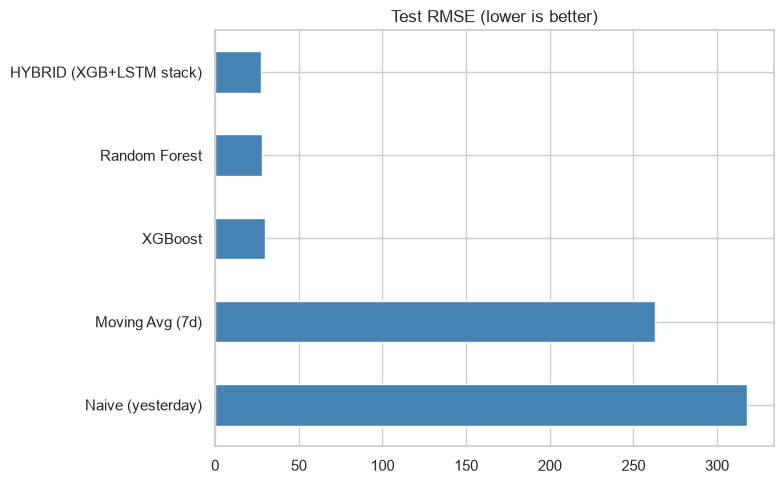

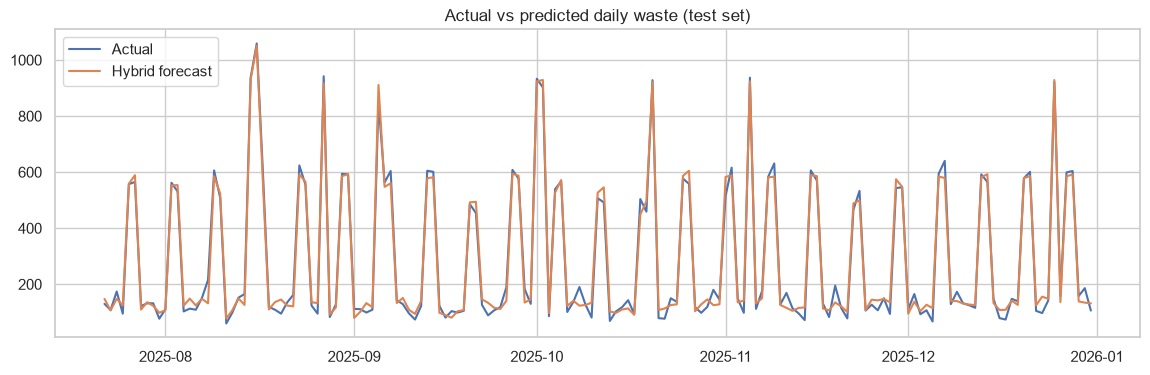

In [13]:
res = pd.DataFrame({k: evaluate(y_te, v) for k, v in preds_test.items()}).T.sort_values("RMSE").round(3)
display(res)

res["RMSE"].sort_values(ascending=False).plot.barh(figsize=(8, 5), title="Test RMSE (lower is better)", color="steelblue")
plt.tight_layout(); plt.show()

best = "HYBRID (XGB+LSTM stack)"
plt.figure(figsize=(14, 4))
plt.plot(te.date, y_te, label="Actual"); plt.plot(te.date, preds_test[best], label="Hybrid forecast")
plt.title("Actual vs predicted daily waste (test set)"); plt.legend(); plt.show()

In [14]:
# Ablation: does adding external signals (weather + holiday) help?
ab = {}
for name, feats in {"History + calendar only": HIST, "History + calendar + external": ALL}.items():
    mdl = XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4, subsample=0.8,
                       colsample_bytree=0.8, random_state=SEED).fit(tr[feats], y_tr)
    ab[name] = evaluate(y_te, mdl.predict(te[feats]))
ab = pd.DataFrame(ab).T.round(3)
display(ab)
gain = (1 - ab.loc["History + calendar + external", "RMSE"] / ab.loc["History + calendar only", "RMSE"]) * 100
print(f"External features reduce RMSE by {gain:.1f}%")

,MAE,RMSE,MAPE%,R2
History + calendar only,111.415,199.945,56.903,0.378
History + calendar + external,23.650,29.690,15.750,0.986


External features reduce RMSE by 85.2%


## 9. Interpretation with SHAP

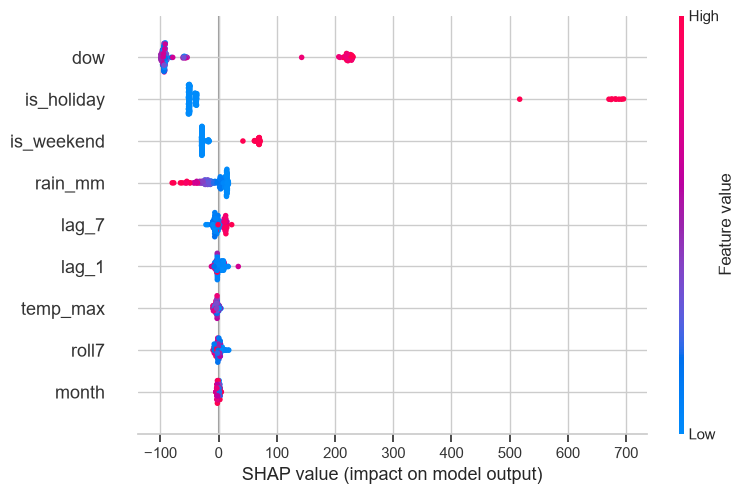

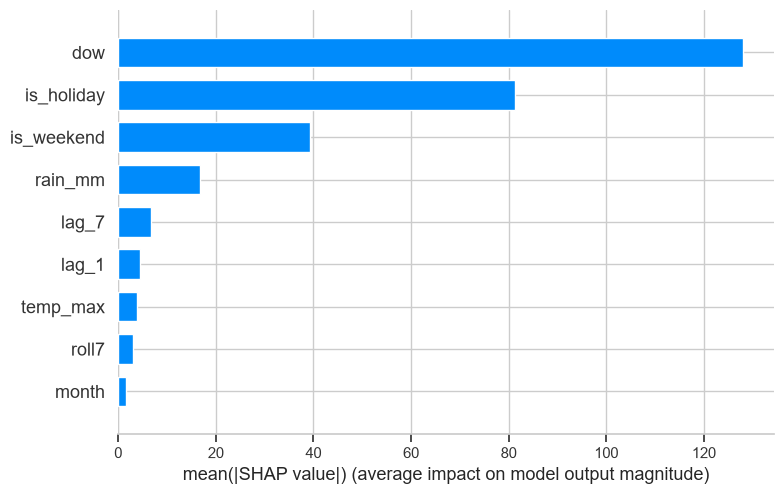

In [15]:
import shap
explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(te[ALL])
shap.summary_plot(sv, te[ALL], show=True)
shap.summary_plot(sv, te[ALL], plot_type="bar", show=True)

## 10. Save artefacts and create the Streamlit dashboard

In [16]:
joblib.dump({"model": xgb, "features": ALL}, "waste_model.joblib")
daily.to_csv("daily_data.csv", index=False)
res.to_csv("model_comparison.csv")
print("Saved waste_model.joblib, daily_data.csv, model_comparison.csv")

Saved waste_model.joblib, daily_data.csv, model_comparison.csv


In [17]:
%%writefile app.py
import streamlit as st, pandas as pd, joblib, plotly.express as px

st.set_page_config(page_title="Food Waste Predictor", layout="wide")
st.title("Food Waste Prediction and Consumption Dashboard")

bundle = joblib.load("waste_model.joblib")
model, feats = bundle["model"], bundle["features"]
df = pd.read_csv("daily_data.csv", parse_dates=["date"])

st.sidebar.header("Tomorrow's conditions")
next_date = df.date.max() + pd.Timedelta(days=1)
temp = st.sidebar.slider("Max temperature (C)", 20.0, 42.0, 32.0)
rain = st.sidebar.slider("Rainfall (mm)", 0.0, 100.0, 0.0)
hol = st.sidebar.checkbox("Holiday / no-class day")

row = {"lag_1": df.waste_units.iloc[-1], "lag_7": df.waste_units.iloc[-7],
       "roll7": df.waste_units.iloc[-7:].mean(), "dow": next_date.dayofweek, "month": next_date.month,
       "is_weekend": int(next_date.dayofweek >= 5), "temp_max": temp, "rain_mm": rain, "is_holiday": int(hol)}
pred = float(model.predict(pd.DataFrame([row])[feats])[0])
usual_prep = df.prepared.tail(30).mean()

c1, c2, c3 = st.columns(3)
c1.metric("Forecast date", next_date.strftime("%d %b %Y"))
c2.metric("Predicted waste (servings)", f"{pred:.0f}")
c3.metric("Suggested cut in preparation", f"{pred*0.8:.0f} servings",
          delta=f"-{pred*0.8/usual_prep*100:.1f}% of usual {usual_prep:.0f}")
if pred > df.waste_units.quantile(0.75):
    st.warning("High waste risk: reduce preparation or plan surplus redistribution.")

st.subheader("Recent waste trend")
st.plotly_chart(px.line(df.tail(90), x="date", y="waste_units"), use_container_width=True)
st.subheader("Average waste by weekday")
st.plotly_chart(px.bar(df.groupby("dow").waste_units.mean().reset_index(), x="dow", y="waste_units"),
                use_container_width=True)

Overwriting app.py


**Run the dashboard:** open a terminal in the notebook folder and run `streamlit run app.py`.

**Next steps:** replace the simulated data in Section 3 with real canteen logs, add Google Trends (`pytrends`) as an extra external feature, and tune the hybrid with `Optuna`.